# Reference-sensitive effect simulations


In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.pipeline import make_pipeline

REPO_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'src').exists())
sys.path.insert(0, str(REPO_ROOT / 'src')) if str(REPO_ROOT / 'src') not in sys.path else None

from data_preparation import (generate_binary_reference_data,
    generate_embedding_like_reference_data, make_mediator_reducer)
from estimate_effects import (DR_RANDOM_STATE, EFFECTS, N_SPLITS, estimate_ci,
    estimate_reference_specific_effects, fixed_hgb_outcome,
    fixed_hgb_propensity, run_specification,
    plot_binary_reference_curves, plot_binary_scale_comparison,
    plot_estimated_vs_true_effects, simulation_result_table,
    plot_nonadditivity_mechanisms)


In [2]:
class ExposureInteractions(BaseEstimator, TransformerMixin):
    """Add A-by-covariate terms without all pairwise interactions."""

    def fit(self, X, y=None):
        self.n_features_in_ = np.asarray(X).shape[1]
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        if X.shape[1] != self.n_features_in_:
            raise ValueError('Unexpected number of outcome-model features')
        return np.column_stack([X, X[:, [0]] * X[:, 1:]])


def logistic_interaction_outcome():
    return make_pipeline(
        ExposureInteractions(), LogisticRegression(max_iter=3000),
    )


def estimate_simulation(simulation):
    """Estimate every nested mean and effect with fixed binary nuisances."""
    roles = simulation['roles']
    result = estimate_reference_specific_effects(
        simulation['data'], roles['outcome'], roles['protected_attribute'],
        roles['mediators'], roles['confounders'], n_splits=N_SPLITS,
        random_state=simulation['provenance']['parameters']['random_state'],
        outcome_model=logistic_interaction_outcome(),
        nested_model=LinearRegression(),
        propensity_model=LogisticRegression(max_iter=3000),
    )
    return result, simulation_result_table(result, simulation['truth'])


## How non-additivity arises

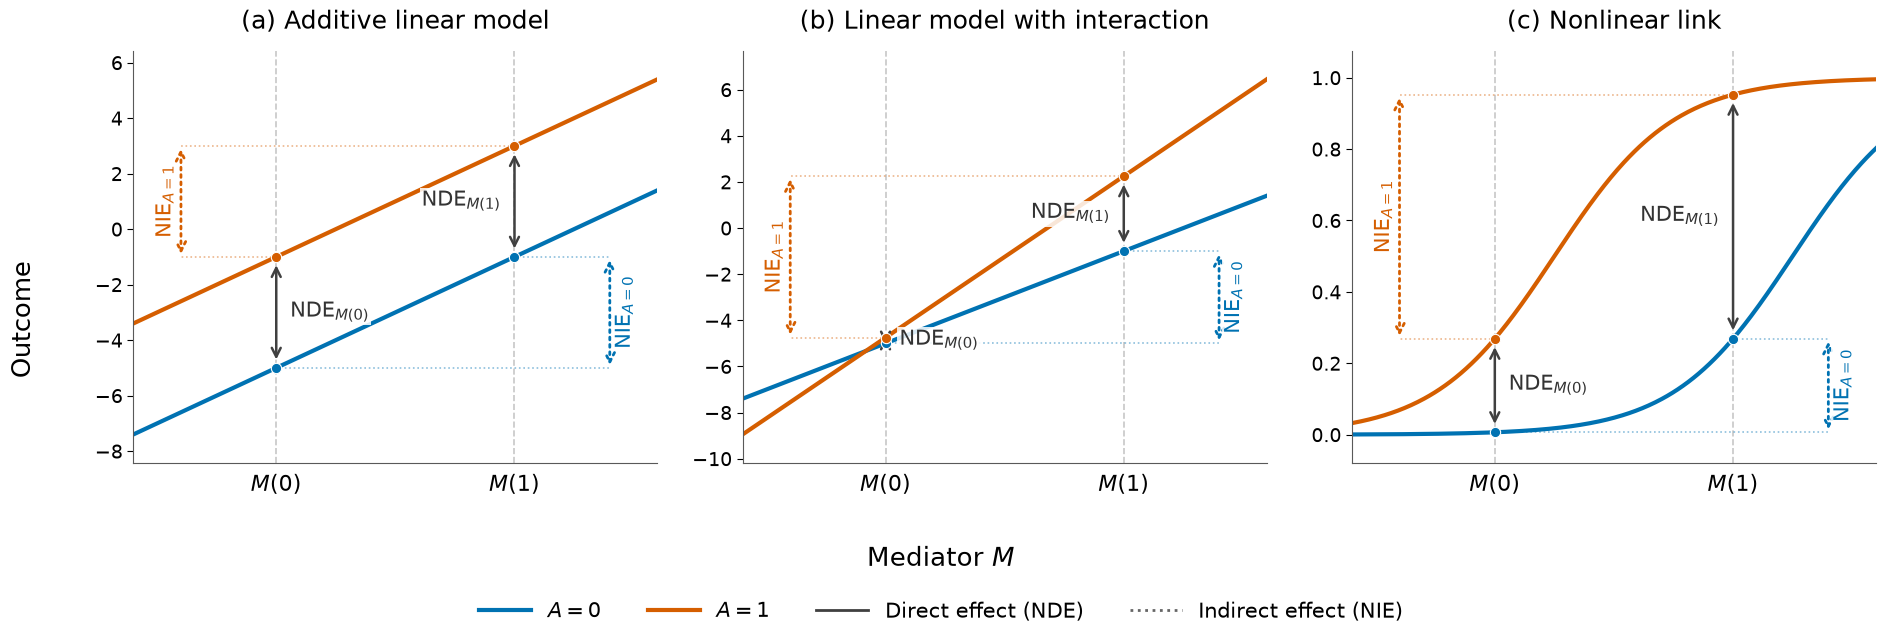

In [3]:
fig, axes = plot_nonadditivity_mechanisms()
plt.show()

# Optional publication exports:
# fig.savefig("nonadditivity_mechanisms.pdf", bbox_inches="tight")
# fig.savefig(
#     "nonadditivity_mechanisms.png",
#     dpi=300,
#     bbox_inches="tight",
# )

## Binary outcome

In [4]:
binary_simulation = generate_binary_reference_data(n=10_000, random_state=31)
binary_result, binary_table = estimate_simulation(binary_simulation)
display(binary_table.round(3))


/Users/282066/Documents/PHD/Distribution_detection/non-additivity-in-causal-fairness/src/estimate_effects/estimation.py:151: RuntimeWarning: More than 5% of propensity estimates were clipped; inspect overlap.
  warnings.warn("More than 5% of propensity estimates were clipped; inspect overlap.", RuntimeWarning)
/Users/282066/Documents/PHD/Distribution_detection/non-additivity-in-causal-fairness/src/estimate_effects/estimation.py:151: RuntimeWarning: More than 5% of propensity estimates were clipped; inspect overlap.
  warnings.warn("More than 5% of propensity estimates were clipped; inspect overlap.", RuntimeWarning)
/Users/282066/Documents/PHD/Distribution_detection/non-additivity-in-causal-fairness/src/estimate_effects/estimation.py:151: RuntimeWarning: More than 5% of propensity estimates were clipped; inspect overlap.
  warnings.warn("More than 5% of propensity estimates were clipped; inspect overlap.", RuntimeWarning)
/Users/282066/Documents/PHD/Distribution_detection/non-additivit

,estimate,truth,ci_low,ci_high
quantity,,,,
psi_00,0.007,0.006,NaN,NaN
psi_01,0.045,0.040,NaN,NaN
psi_10,0.207,0.181,NaN,NaN
psi_11,0.520,0.498,NaN,NaN
nde_m0,0.200,0.175,0.173,0.226
nde_m1,0.474,0.459,0.439,0.510
nie_a0,0.038,0.033,0.010,0.066
nie_a1,0.313,0.317,0.287,0.339
interaction,0.275,0.284,0.237,0.312


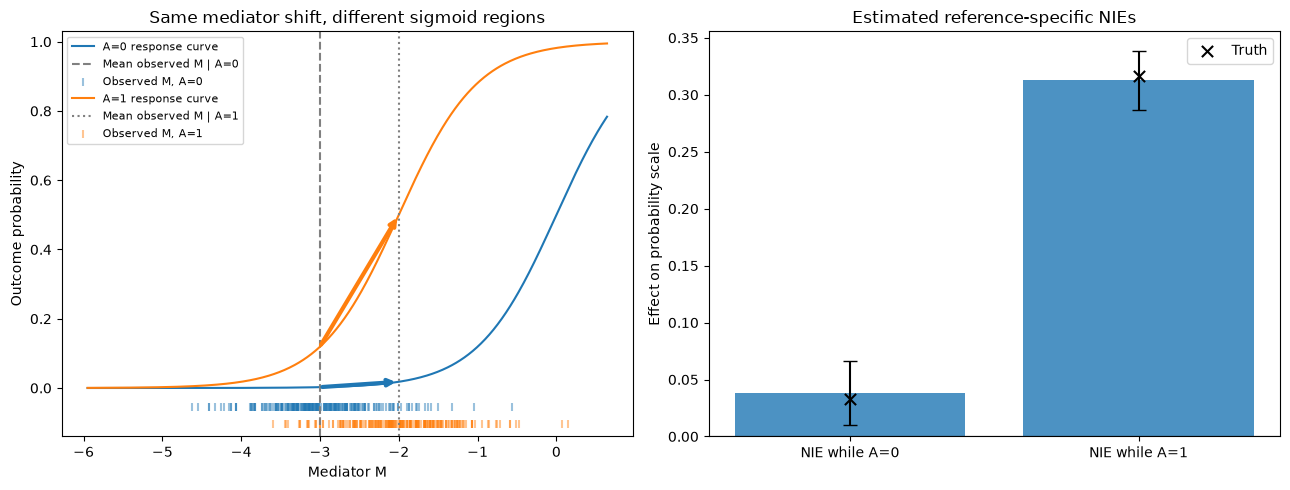

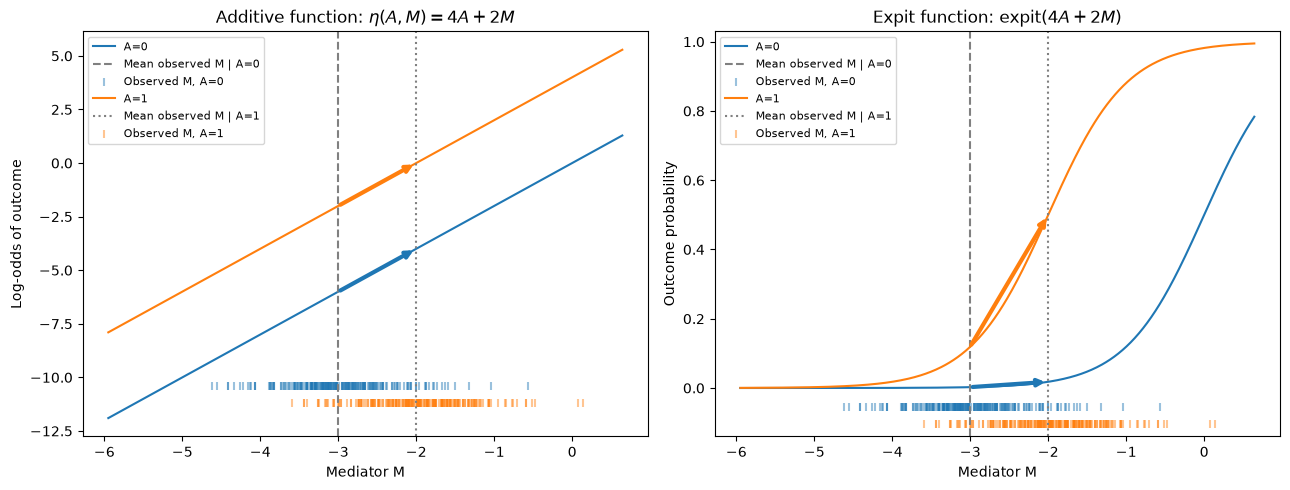

In [5]:
plot_binary_reference_curves(binary_simulation, binary_table)
plt.show()
plot_binary_scale_comparison(binary_simulation)
plt.show()

## Neural-network high-dimensional mediators

In [6]:
embedding_simulation = generate_embedding_like_reference_data(
    n=100_000, mediator_dim=500, mediator_hidden_dims=(16,),
    outcome_hidden_dims=(16,), random_state=42,
)
embedding_roles = embedding_simulation['roles']
pca_reducer = make_mediator_reducer('pca', .70, random_state=DR_RANDOM_STATE)
embedding_result = estimate_reference_specific_effects(
    embedding_simulation['data'], embedding_roles['outcome'],
    embedding_roles['protected_attribute'], embedding_roles['mediators'],
    embedding_roles['confounders'], transformer=pca_reducer,
    n_splits=N_SPLITS, random_state=DR_RANDOM_STATE, propensity_clip=.01,
    outcome_model=logistic_interaction_outcome(),
    propensity_model=LogisticRegression(max_iter=3000),
)
embedding_table = simulation_result_table(
    embedding_result, embedding_simulation['truth'],
)
embedding_table['error'] = embedding_table['estimate'] - embedding_table['truth']
display(embedding_table.round(4))


,estimate,truth,ci_low,ci_high,error
quantity,,,,,
psi_00,0.4384,0.4397,NaN,NaN,-0.0013
psi_01,0.6818,0.6884,NaN,NaN,-0.0066
psi_10,0.4946,0.4908,NaN,NaN,0.0038
psi_11,0.8678,0.8702,NaN,NaN,-0.0024
nde_m0,0.0562,0.0512,0.0496,0.0628,0.0051
nde_m1,0.1860,0.1818,0.1786,0.1935,0.0042
nie_a0,0.2434,0.2487,0.2370,0.2497,-0.0053
nie_a1,0.3732,0.3794,0.3678,0.3785,-0.0062
interaction,0.1298,0.1307,0.1227,0.1369,-0.0009


In [7]:
pca_diagnostics = embedding_result['diagnostics']['psi_00']
display(pd.DataFrame({
    'fold': range(1, N_SPLITS + 1),
    'selected_components': pca_diagnostics['mediator_dimensions_by_fold'],
    'retained_variance': pca_diagnostics['mediator_explained_variance_by_fold'],
}).round(4))
display(pd.DataFrame(embedding_result['diagnostics']).T[[
    'fraction_propensity_c_clipped', 'fraction_propensity_mc_clipped',
    'max_absolute_weight', 'effective_sample_size',
]].round(4))

,fold,selected_components,retained_variance
0,1,335,0.7006
1,2,335,0.7005
2,3,335,0.7006
3,4,335,0.7005
4,5,335,0.7005


,fraction_propensity_c_clipped,fraction_propensity_mc_clipped,max_absolute_weight,effective_sample_size
psi_00,0.0,0.0043,11.415591,45245.85219
psi_01,0.0,0.0043,179.388534,8443.399234
psi_10,0.0,0.0043,131.093394,8699.698176
psi_11,0.0,0.0043,10.229453,45578.514635


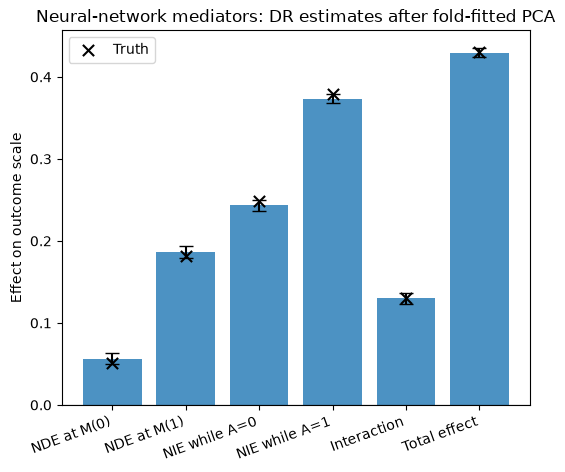

In [8]:
embedding_effects = ['nde_m0', 'nde_m1', 'nie_a0', 'nie_a1', 'interaction', 'total_effect']
embedding_labels = ['NDE at M(0)', 'NDE at M(1)', 'NIE while A=0',
                    'NIE while A=1', 'Interaction', 'Total effect']
plot_estimated_vs_true_effects([
    (embedding_table, embedding_effects, embedding_labels,
     'Neural-network mediators: DR estimates after fold-fitted PCA'),
])
plt.xticks(rotation=20, ha='right')
plt.show()

## Minimal binary-data specification checks

Both binary DGPs use logistic regression with explicit exposure interactions as the primary outcome model. Each setting has one fixed HGB outcome alternative. Propensity models are logistic in every primary specification; one sensitivity per setting changes only $P(A\mid M,C)$ to a fixed HGB classifier while retaining logistic $P(A\mid C)$. High-dimensional reduction checks retain the primary logistic outcome model. HGB configurations are fixed in advance and are never chosen using causal-effect recovery.


In [9]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

REPO_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'src').exists())
sys.path.insert(0, str(REPO_ROOT / 'src')) if str(REPO_ROOT / 'src' ) not in sys.path else None

from data_preparation import (
    generate_embedding_like_reference_data,
    make_mediator_reducer,
    generate_binary_reference_data,
)
from estimate_effects import estimate_reference_specific_effects


In [10]:
low_dimensional_simulation = generate_binary_reference_data(
    n=15_000,
    mediator_dim=6,
    exposure_logit_effect=4.0,
    mediator_logit_effect=2.0,
    mediator_intercept=-1.0,
    mediator_shift=.3,
    mediator_noise_sd=.8,
    random_state=31,
)

low_dimensional_specifications = [
    {
        'id': 'L-S1',
        'setting': 'low dimensional binary',
        'specification': 'Primary',
        'outcome_model': 'Logistic + A interactions',
        'propensity_model': 'Logistic',
        'reduction': 'None',
        'options': {
            'outcome_model': logistic_interaction_outcome(),
            'propensity_model': LogisticRegression(max_iter=3000),
        },
    },
    {
        'id': 'L-S2',
        'setting': 'low dimensional binary',
        'specification': 'Outcome sensitivity',
        'outcome_model': 'HGB (fixed)',
        'propensity_model': 'Logistic',
        'reduction': 'None',
        'options': {
            'outcome_model': fixed_hgb_outcome(),
            'propensity_model': LogisticRegression(max_iter=3000),
        },
    },
    {
        'id': 'L-S3',
        'setting': 'low dimensional binary',
        'specification': 'Propensity sensitivity',
        'outcome_model': 'Logistic + A interactions',
        'propensity_model': 'Logistic C; HGB MC',
        'reduction': 'None',
        'options': {
            'outcome_model': logistic_interaction_outcome(),
            'propensity_model': LogisticRegression(max_iter=3000),
            'propensity_mc_model': fixed_hgb_propensity(),
        },
    },
]

low_dimensional_rows = [
    run_specification(low_dimensional_simulation, specification)
    for specification in low_dimensional_specifications
]


In [11]:
high_dimensional_simulation = generate_embedding_like_reference_data(
    n=50_000, mediator_dim=500, mediator_hidden_dims=(16,),
    outcome_hidden_dims=(16,), random_state=42,
)


def pca(fraction):
    return make_mediator_reducer('pca', fraction, random_state=DR_RANDOM_STATE)


def high_specification(identifier, specification, reduction, transformer=None,
                       outcome_sensitivity=False, propensity_sensitivity=False):
    options = {
        'outcome_model': (
            fixed_hgb_outcome() if outcome_sensitivity
            else logistic_interaction_outcome()
        ),
        'propensity_model': LogisticRegression(max_iter=3000),
    }
    if transformer is not None:
        options['transformer'] = transformer
    if propensity_sensitivity:
        options['propensity_mc_model'] = fixed_hgb_propensity()
    return {
        'id': identifier,
        'setting': 'high dimensional binary',
        'specification': specification,
        'outcome_model': (
            'HGB (fixed)' if outcome_sensitivity
            else 'Logistic + A interactions'
        ),
        'propensity_model': (
            'Logistic C; HGB MC' if propensity_sensitivity else 'Logistic'
        ),
        'reduction': reduction,
        'options': options,
    }


high_dimensional_specifications = [
    high_specification('H-S1', 'Primary', 'PCA 70%', pca(.70)),
    high_specification('H-S2', 'PCA lower', 'PCA 60%', pca(.60)),
    high_specification('H-S3', 'PCA higher', 'PCA 90%', pca(.90)),
    high_specification(
        'H-S4', 'PFI alternative', 'PFI 20%',
        make_mediator_reducer(
            'pfi', .20, random_state=DR_RANDOM_STATE,
            n_repeats=2, max_iter=75,
        ),
    ),
    high_specification('H-S5', 'No reduction', 'None'),
    high_specification(
        'H-S6', 'Propensity sensitivity', 'PCA 70%', pca(.70),
        propensity_sensitivity=True,
    ),
    high_specification(
        'H-S7', 'Outcome sensitivity', 'PCA 70%', pca(.70),
        outcome_sensitivity=True,
    ),
]

high_dimensional_rows = [
    run_specification(high_dimensional_simulation, specification)
    for specification in high_dimensional_specifications
]


In [12]:
robustness_results = pd.DataFrame(low_dimensional_rows + high_dimensional_rows)

front = [
    'id', 'setting', 'specification', 'input_dim', 'outcome_model',
    'propensity_model', 'reduction', 'reduced_dim_min', 'reduced_dim_max',
]
diagnostics = [
    'outcome_log_loss', 'min_ess', 'max_clipping',
    'propensity_c_roc_auc', 'propensity_c_brier_score',
    'propensity_mc_roc_auc', 'propensity_mc_brier_score',
    'mean_absolute_effect_error',
]
effect_columns = [
    f'{effect}_{suffix}'
    for effect in EFFECTS
    for suffix in ('estimate', 'ci_low', 'ci_high', 'truth', 'error')
]
robustness_results = robustness_results[front + effect_columns + diagnostics]

output_dir = REPO_ROOT / 'results' / 'assessment'
output_dir.mkdir(parents=True, exist_ok=True)
robustness_path = output_dir / 'simulation_robustness.csv'
robustness_results.to_csv(robustness_path, index=False)


display_table = robustness_results[front].copy()
display_table['reduced_dim'] = display_table.apply(
    lambda row: str(int(row.reduced_dim_min))
    if row.reduced_dim_min == row.reduced_dim_max
    else f"{int(row.reduced_dim_min)}-{int(row.reduced_dim_max)}",
    axis=1,
)
display_table = display_table.drop(
    columns=['input_dim', 'propensity_model', 'reduced_dim_min', 'reduced_dim_max'],
)
for effect in EFFECTS:
    display_table[effect] = robustness_results.apply(
        lambda row, effect=effect: estimate_ci(row, effect), axis=1,
    )
display_table['outcome_log_loss'] = robustness_results['outcome_log_loss'].round(3)
display_table['min_ess'] = robustness_results['min_ess'].round(1)
display_table['max_clipping'] = robustness_results['max_clipping'].round(3)
display_table['propensity_mc_brier'] = robustness_results['propensity_mc_brier_score'].round(3)
display_table['mean_absolute_effect_error'] = robustness_results['mean_absolute_effect_error'].round(3)

display(display_table)
print(f'Saved complete numeric results to {robustness_path.relative_to(REPO_ROOT)}')


,id,setting,specification,outcome_model,reduction,reduced_dim,nde_m0,nde_m1,nie_a0,nie_a1,interaction,outcome_log_loss,min_ess,max_clipping,propensity_mc_brier,mean_absolute_effect_error
0,L-S1,low dimensional binary,Primary,Logistic + A interactions,None,6,"0.682 [0.651, 0.713]","0.618 [0.599, 0.637]","0.147 [0.132, 0.163]","0.083 [0.056, 0.110]","-0.064 [-0.095, -0.034]",0.356,707.2,0.015,0.126,0.006
1,L-S2,low dimensional binary,Outcome sensitivity,HGB (fixed),None,6,"0.681 [0.649, 0.714]","0.617 [0.598, 0.637]","0.148 [0.133, 0.164]","0.084 [0.056, 0.113]","-0.064 [-0.096, -0.032]",0.360,707.2,0.015,0.126,0.007
2,L-S3,low dimensional binary,Propensity sensitivity,Logistic + A interactions,None,6,"0.687 [0.663, 0.710]","0.617 [0.599, 0.635]","0.149 [0.135, 0.162]","0.079 [0.061, 0.098]","-0.070 [-0.092, -0.047]",0.356,983.9,0.001,0.127,0.008
3,H-S1,high dimensional binary,Primary,Logistic + A interactions,PCA 70%,329,"0.059 [0.049, 0.068]","0.178 [0.168, 0.188]","0.253 [0.244, 0.261]","0.372 [0.364, 0.380]","0.119 [0.110, 0.129]",0.386,3994.6,0.004,0.165,0.006
4,H-S2,high dimensional binary,PCA lower,Logistic + A interactions,PCA 60%,276-277,"0.063 [0.054, 0.073]","0.180 [0.170, 0.190]","0.251 [0.243, 0.259]","0.368 [0.360, 0.375]","0.117 [0.107, 0.126]",0.386,4075.8,0.004,0.165,0.008
5,H-S3,high dimensional binary,PCA higher,Logistic + A interactions,PCA 90%,440,"0.052 [0.042, 0.061]","0.176 [0.165, 0.186]","0.255 [0.246, 0.264]","0.379 [0.371, 0.387]","0.124 [0.114, 0.135]",0.386,3872.3,0.005,0.165,0.004
6,H-S4,high dimensional binary,PFI alternative,Logistic + A interactions,PFI 20%,100,"0.229 [0.218, 0.240]","0.279 [0.269, 0.289]","0.151 [0.143, 0.158]","0.201 [0.193, 0.208]","0.050 [0.040, 0.060]",0.451,6820.3,0.000,0.187,0.126
7,H-S5,high dimensional binary,No reduction,Logistic + A interactions,None,500,"0.049 [0.039, 0.058]","0.172 [0.161, 0.183]","0.259 [0.250, 0.268]","0.382 [0.374, 0.390]","0.123 [0.113, 0.134]",0.387,3643.3,0.006,0.165,0.006
8,H-S6,high dimensional binary,Propensity sensitivity,Logistic + A interactions,PCA 70%,329,"0.060 [0.050, 0.069]","0.176 [0.167, 0.185]","0.255 [0.247, 0.262]","0.371 [0.364, 0.379]","0.116 [0.108, 0.125]",0.386,6473.8,0.000,0.163,0.008
9,H-S7,high dimensional binary,Outcome sensitivity,HGB (fixed),PCA 70%,329,"0.050 [0.039, 0.061]","0.176 [0.166, 0.186]","0.254 [0.246, 0.263]","0.380 [0.373, 0.388]","0.126 [0.116, 0.137]",0.398,3994.6,0.004,0.165,0.004


Saved complete numeric results to results/assessment/simulation_robustness.csv
